In [222]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns
import re

In [223]:
df = pd.read_csv("/Users/admin/Documents/ML Engineer/Practice/Data Cleaning/bi.csv", encoding='utf-8', encoding_errors="replace")
df.head()

,fNAME,lNAME,Age,gender,country,residence,entryEXAM,prevEducation,studyHOURS,Python,DB
0,Christina,Binger,44,Female,Norway,Private,72,Masters,158,59.0,55
1,Alex,Walekhwa,60,M,Kenya,Private,79,Diploma,150,60.0,75
2,Philip,Leo,25,Male,Uganda,Sognsvann,55,HighSchool,130,74.0,50
3,Shoni,Hlongwane,22,F,Rsa,Sognsvann,40,High School,120,NaN,44
4,Maria,Kedibone,23,Female,South Africa,Sognsvann,65,High School,122,91.0,80


In [224]:
df = df.rename(columns={
    'fNAME': 'first_name',
    'lNAME': 'last_name',
    "entryEXAM": "entry_exam",
    "prevEducation": "prev_education",
    "studyHOURS": "study_hours"
})

In [225]:
df.columns = df.columns.str.lower()
df.head()

,first_name,last_name,age,gender,country,residence,entry_exam,prev_education,study_hours,python,db
0,Christina,Binger,44,Female,Norway,Private,72,Masters,158,59.0,55
1,Alex,Walekhwa,60,M,Kenya,Private,79,Diploma,150,60.0,75
2,Philip,Leo,25,Male,Uganda,Sognsvann,55,HighSchool,130,74.0,50
3,Shoni,Hlongwane,22,F,Rsa,Sognsvann,40,High School,120,NaN,44
4,Maria,Kedibone,23,Female,South Africa,Sognsvann,65,High School,122,91.0,80


In [226]:
df['first_name'] = df['first_name'].str.replace("[^A-Za-z]", "", regex=True)
df['last_name'] = df['last_name'].str.replace("[^A-Za-z]", "", regex=True)

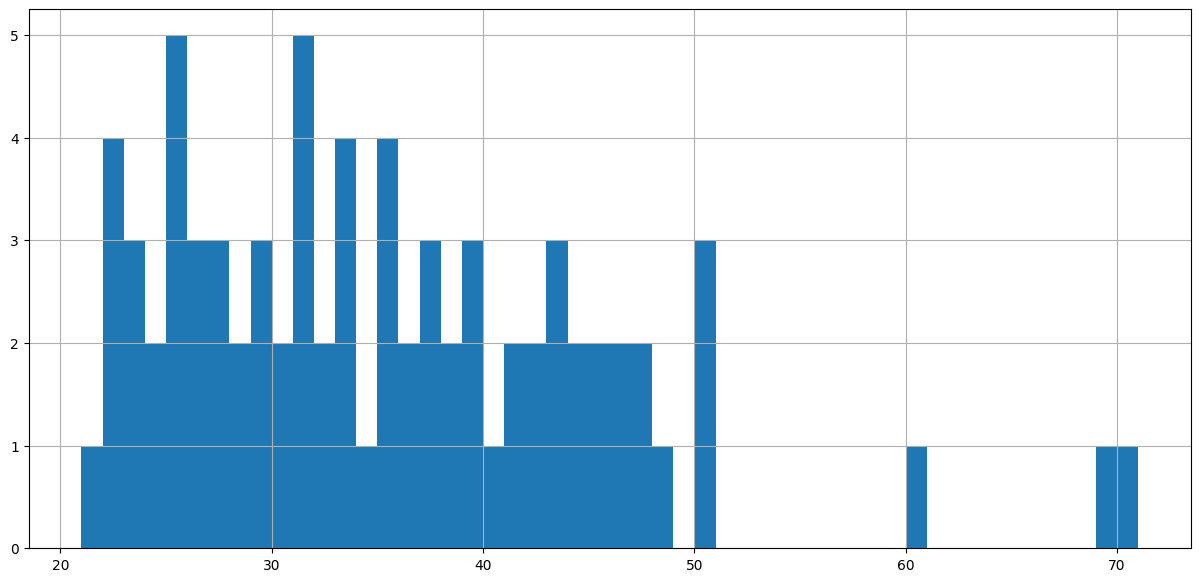

In [227]:
plt.figure(figsize=(15, 7))

df['age'].hist(bins=50)
plt.show()

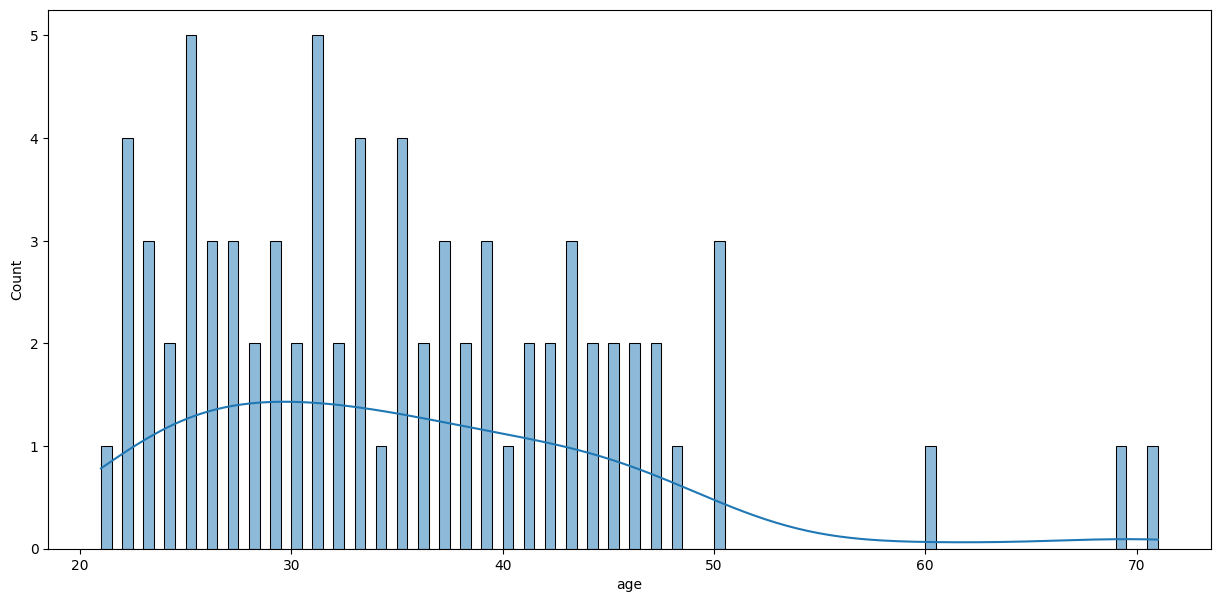

In [228]:
plt.figure(figsize=(15,7))
sns.histplot(data=df, x='age', bins=100, kde=True)
plt.show()

In [229]:
df['gender'].value_counts()

gender
Female    41
Male      32
M          1
F          1
female     1
male       1
Name: count, dtype: int64

In [230]:
df['gender'] = df['gender'].replace({
    'female': 'F',
    'Female': 'F',
    'male': 'M', 
    'Male': 'M'
    })

df['gender'].value_counts()

gender
F    43
M    34
Name: count, dtype: int64

In [231]:
def clean_gender(value):
    if value.lower() in ['female', 'f']:
        return 'F'
    
    elif value.lower() in ['male', 'm']:
        return 'M'
    
    else:
        None


df['gender'] = df['gender'].apply(clean_gender)

In [232]:
df['gender'].value_counts()

gender
F    43
M    34
Name: count, dtype: int64

In [233]:
df['prev_education'].value_counts()

prev_education
Bachelors       24
High School     18
Masters         16
Diploma          9
Doctorate        5
HighSchool       1
Barrrchelors     1
diploma          1
DIPLOMA          1
Diplomaaa        1
Name: count, dtype: int64

In [234]:
def clean_education(value):
    if value in ['diploma', 'DIPLOMA', 'Diplomaaa', 'Diploma']:
        return 'Diploma'
    
    elif value in ['HighSchool', 'High School']:
        return 'High School'

    elif value in ['Barrrchelors']:
        return 'Bachelors'
    
    return value

df['prev_education'] = df['prev_education'].apply(clean_education)


In [235]:
df['prev_education'].value_counts()

prev_education
Bachelors      25
High School    19
Masters        16
Diploma        12
Doctorate       5
Name: count, dtype: int64

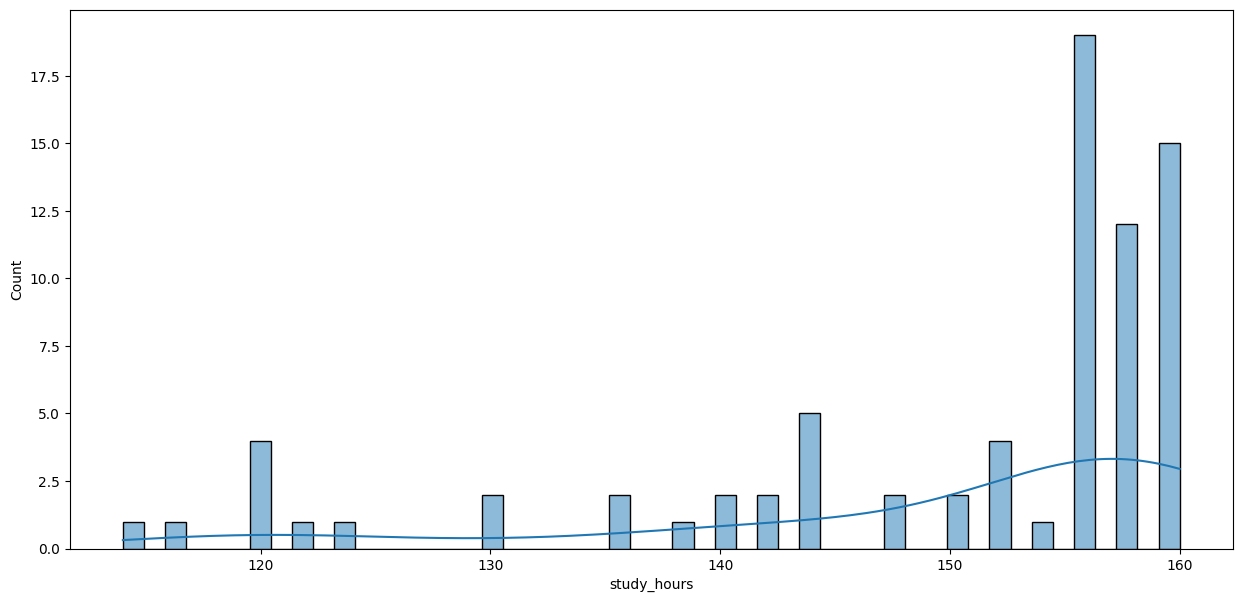

In [236]:
plt.figure(figsize=(15,7))
sns.histplot(data=df, x='study_hours', bins=50, kde=True)
plt.show()

In [237]:
df['python'] = pd.to_numeric(df['python'])
df['python'] = df['python'].fillna(df['python'].mean())

In [238]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 77 entries, 0 to 76
Data columns (total 11 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   first_name      77 non-null     object 
 1   last_name       77 non-null     object 
 2   age             77 non-null     int64  
 3   gender          77 non-null     object 
 4   country         77 non-null     object 
 5   residence       77 non-null     object 
 6   entry_exam      77 non-null     int64  
 7   prev_education  77 non-null     object 
 8   study_hours     77 non-null     int64  
 9   python          77 non-null     float64
 10  db              77 non-null     int64  
dtypes: float64(1), int64(4), object(6)
memory usage: 6.7+ KB
